# Conversão para HSV

In [ ]:
import sys
from pathlib import Path

# O kernel inicia na pasta DESTE caderno — localiza a raiz do projeto:
RAIZ = Path.cwd()
if not (RAIZ / "src" / "leitura.py").exists():
    RAIZ = RAIZ.parent          # kernel começou dentro de notebooks/
sys.path.insert(0, str(RAIZ))   # raiz no path -> 'from src...' funciona

# Imports padrão de todos os cadernos:
from src.leitura import (PASTA_IMAGENS, PASTA_RESULTADOS, carregar_imagem,
                         nome_da_mascara, criar_pastas_resultados, auditar_base)
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("raiz do projeto:", RAIZ)

In [3]:
import cv2
from pathlib import Path

from src.leitura import PASTA_IMAGENS, PASTA_RESULTADOS, carregar_imagem, nome_da_mascara, criar_pastas_resultados
from src.preprocessamento import para_hsv

criar_pastas_resultados()   # recria a árvore — agora inclui resultados/hsv/

Árvore de resultados pronta em: /home/isadora/Documentos/ProcessIMg/resultados


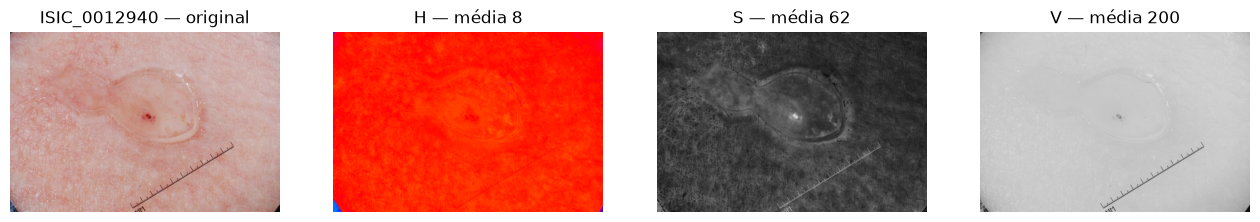

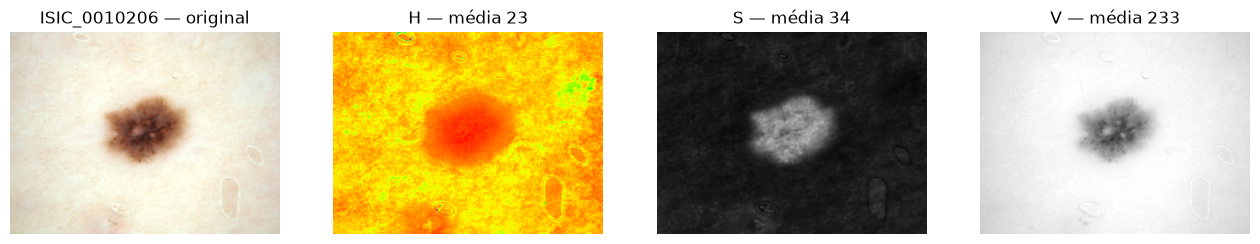

In [4]:
alvo = PASTA_RESULTADOS / "hsv"

for nome in ["ISIC_0012940.jpg", "ISIC_0010206.jpg"]:
    img = carregar_imagem(PASTA_IMAGENS / nome)
    hsv = para_hsv(img)
    h, s, v = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]

    fig, axes = plt.subplots(1, 4, figsize=(16, 5))
    axes[0].imshow(img)
    axes[0].set_title(f"{Path(nome).stem} — original")
    for ax, canal, letra in zip(axes[1:], [h, s, v], ["H", "S", "V"]):
        if letra == "H":   # matiz é ângulo: colormap circular, range [0,179] do OpenCV
            ax.imshow(canal, cmap="hsv", vmin=0, vmax=179)
        else:
            ax.imshow(canal, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{letra} — média {canal.mean():.0f}")
    for ax in axes:
        ax.axis("off")
    fig.savefig(alvo / f"{Path(nome).stem}_hsv.png", bbox_inches="tight", dpi=150)
    plt.show()
    plt.close(fig)

In [5]:
# ATENÇÃO ao sinal do S: descoberta deste passo (lesão MAIS saturada que a pele)
for nome in ["ISIC_0012940.jpg", "ISIC_0010206.jpg"]:
    hsv = para_hsv(carregar_imagem(PASTA_IMAGENS / nome))
    msk = cv2.imread(str(nome_da_mascara(PASTA_IMAGENS / nome)), cv2.IMREAD_GRAYSCALE)

    print(f"--- {Path(nome).stem} ---")
    for canal, letra in zip([hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]], ["H", "S", "V"]):
        dentro = canal[msk > 0].mean()
        fora = canal[msk == 0].mean()
        print(f"{letra}: lesão {dentro:.1f} | pele {fora:.1f} | pele - lesão {fora - dentro:+.1f}")

--- ISIC_0012940 ---
H: lesão 6.4 | pele 7.9 | pele - lesão +1.5
S: lesão 89.0 | pele 61.0 | pele - lesão -28.1
V: lesão 198.3 | pele 200.2 | pele - lesão +1.8
--- ISIC_0010206 ---
H: lesão 10.4 | pele 24.1 | pele - lesão +13.7
S: lesão 122.5 | pele 26.4 | pele - lesão -96.1
V: lesão 160.6 | pele 238.9 | pele - lesão +78.3
